
# AURORA cfDNA Regional Fragmentation Analysis  
## Step 2: PCA + chromosome/arm-level patient-clustered models

This notebook builds on Step 1 outputs.

### Main purpose

Before testing thousands of individual genomic bins, Step 2 evaluates whether **lower-dimensional regional fragmentation patterns** are associated with:

1. Treatment context, adjusted for tumor fraction  
2. Tumor fraction, adjusted for treatment context  
3. Repeated sampling, accounted for by clustering on `Patient_Identifier`

### Analyses included

1. Load Step 1 analysis-ready annotation and chromosome/arm summary matrices  
2. Fit patient-clustered models for chromosome-level summaries  
3. Fit patient-clustered models for chromosome-arm-level summaries  
4. Run PCA on chromosome-arm matrices  
5. Model PCs against treatment context and tumor fraction  
6. Generate PCA plots, coefficient plots, and summary tables  

### Model

For each chromosome, chromosome arm, or PC:

```text
regional_feature ~ Treatment context + Tumor fraction (%)
clustered by Patient_Identifier
```

Treatment context reference group:

```text
Pre-treatment
```

### Important note

This step is still **low-dimensional regional modeling**.  
Bin-level genome-wide screening should come after this, in Step 3.


In [1]:

# ============================================================
# STEP 1: Setup paths, parameters, imports, and helper functions
# ============================================================

from pathlib import Path
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

print("Step 2 notebook started:", time.ctime())

# -------------------------
# Paths
# -------------------------

OUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/Result"
)

STEP1_TABLE_DIR = OUT_DIR / "Step1_QC_tables"

STEP2_TABLE_DIR = OUT_DIR / "Step2_PCA_arm_chrom_models_tables"
STEP2_PLOT_DIR = OUT_DIR / "Step2_PCA_arm_chrom_models_plots"

for d in [STEP2_TABLE_DIR, STEP2_PLOT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# -------------------------
# Key Step 1 files
# -------------------------

ANNO_FILE = STEP1_TABLE_DIR / "01_analysis_ready_sample_annotation.csv"

CHROM_RAW_FILE = STEP1_TABLE_DIR / "01_chromosome_level_raw_short_long_ratio_matrix.csv"
ARM_RAW_FILE = STEP1_TABLE_DIR / "01_chromosome_arm_level_raw_short_long_ratio_matrix.csv"

CHROM_CENTERED_FILE = STEP1_TABLE_DIR / "01_chromosome_level_sample_centered_short_long_ratio_matrix.csv"
ARM_CENTERED_FILE = STEP1_TABLE_DIR / "01_chromosome_arm_level_sample_centered_short_long_ratio_matrix.csv"

# -------------------------
# Parameters
# -------------------------

TREATMENT_ORDER = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment",
]

TFX_COL = "Tumor_Fraction_percent_from_CNV_annotation"

REFERENCE_TREATMENT = "Pre-treatment"

FDR_ALPHA = 0.05

N_PCS = 10

MIN_PATIENT_CLUSTERS = 20

# For low-dimensional chromosome and arm models, GEE is feasible.
MODEL_ENGINE = "gee"  # options: "gee" or "cluster_ols"

# -------------------------
# Check files
# -------------------------

required_files = [
    ANNO_FILE,
    CHROM_RAW_FILE,
    ARM_RAW_FILE,
    CHROM_CENTERED_FILE,
    ARM_CENTERED_FILE,
]

for p in required_files:
    if not p.exists():
        raise FileNotFoundError(f"Missing required Step 1 output: {p}")
    print("Found:", p)

print("\nStep 2 output table directory:", STEP2_TABLE_DIR)
print("Step 2 output plot directory:", STEP2_PLOT_DIR)

# -------------------------
# Helper functions
# -------------------------

def chrom_sort_key(chrom):
    chrom = str(chrom).replace("chr", "")
    if chrom.endswith("p") or chrom.endswith("q"):
        chrom = chrom[:-1]
    if chrom.isdigit():
        return int(chrom)
    if chrom == "X":
        return 23
    if chrom == "Y":
        return 24
    if chrom in ["M", "MT"]:
        return 25
    return 999


def arm_sort_key(x):
    x = str(x)
    if x.endswith("p") or x.endswith("q"):
        return (chrom_sort_key(x[:-1]), x[-1])
    return (chrom_sort_key(x), "")


def clean_feature_name_for_formula(x):
    """
    Convert a feature name into a safe temporary column name.
    """
    return re.sub(r"[^A-Za-z0-9_]+", "_", str(x))


def add_fdr(df, p_col, q_col):
    df[q_col] = np.nan
    ok = df[p_col].notna()
    if ok.sum() > 0:
        df.loc[ok, q_col] = multipletests(
            df.loc[ok, p_col].astype(float).values,
            method="fdr_bh"
        )[1]
    return df


def fit_clustered_model(feature_values, annot_df, feature_name, feature_type, matrix_type, engine=MODEL_ENGINE):
    """
    Fit:
        feature ~ treatment_context + tumor_fraction
    clustered by Patient_Identifier.

    For low-dimensional chromosome/arm/PC features, GEE is preferred.
    """
    df = annot_df[
        ["Barcode", "Patient_Identifier", "Treatment_Context_3group", TFX_COL]
    ].copy()

    df["feature_value"] = pd.to_numeric(feature_values, errors="coerce")
    df[TFX_COL] = pd.to_numeric(df[TFX_COL], errors="coerce")
    df["Patient_Identifier"] = df["Patient_Identifier"].astype(str)

    df["Treatment_Context_3group"] = pd.Categorical(
        df["Treatment_Context_3group"],
        categories=TREATMENT_ORDER,
        ordered=True,
    )

    df = df.dropna(
        subset=[
            "feature_value",
            "Patient_Identifier",
            "Treatment_Context_3group",
            TFX_COL,
        ]
    ).copy()

    n_samples = df.shape[0]
    n_patients = df["Patient_Identifier"].nunique()

    treatment_counts = df["Treatment_Context_3group"].value_counts().to_dict()

    base = {
        "feature": feature_name,
        "feature_type": feature_type,
        "matrix_type": matrix_type,
        "model_engine": engine,
        "n_samples": n_samples,
        "n_patients": n_patients,
        "n_pre": treatment_counts.get("Pre-treatment", 0),
        "n_on": treatment_counts.get("On-treatment", 0),
        "n_post_off": treatment_counts.get("Post-treatment/off-treatment", 0),
        "model_status": "not_run",
        "model_error": "",
        "coef_on_vs_pre": np.nan,
        "p_on_vs_pre": np.nan,
        "coef_post_off_vs_pre": np.nan,
        "p_post_off_vs_pre": np.nan,
        "coef_tumor_fraction_percent": np.nan,
        "p_tumor_fraction_percent": np.nan,
        "wald_chi2_treatment_overall": np.nan,
        "p_treatment_overall": np.nan,
    }

    if n_patients < MIN_PATIENT_CLUSTERS:
        base["model_status"] = "skipped_too_few_patient_clusters"
        base["model_error"] = f"n_patients={n_patients} < {MIN_PATIENT_CLUSTERS}"
        return base

    if df["Treatment_Context_3group"].nunique() < 2:
        base["model_status"] = "skipped_too_few_treatment_groups"
        return base

    if df["feature_value"].std(skipna=True) == 0 or pd.isna(df["feature_value"].std(skipna=True)):
        base["model_status"] = "skipped_zero_variance"
        return base

    formula = (
        'feature_value ~ C(Treatment_Context_3group, Treatment(reference="Pre-treatment"))'
        f' + {TFX_COL}'
    )

    try:
        if engine == "gee":
            model = smf.gee(
                formula=formula,
                groups="Patient_Identifier",
                data=df,
                family=sm.families.Gaussian(),
                cov_struct=sm.cov_struct.Exchangeable(),
            )
            res = model.fit(maxiter=100)

        elif engine == "cluster_ols":
            model = smf.ols(formula=formula, data=df)
            res = model.fit(
                cov_type="cluster",
                cov_kwds={"groups": df["Patient_Identifier"]},
            )

        else:
            raise ValueError("engine must be 'gee' or 'cluster_ols'")

        base["model_status"] = "ok"

        param_names = list(res.params.index)

        def find_param(term):
            for p in param_names:
                if term in p:
                    return p
            return None

        on_param = find_param("On-treatment")
        post_param = find_param("Post-treatment/off-treatment")

        if on_param is not None:
            base["coef_on_vs_pre"] = float(res.params[on_param])
            base["p_on_vs_pre"] = float(res.pvalues[on_param])

        if post_param is not None:
            base["coef_post_off_vs_pre"] = float(res.params[post_param])
            base["p_post_off_vs_pre"] = float(res.pvalues[post_param])

        if TFX_COL in res.params.index:
            base["coef_tumor_fraction_percent"] = float(res.params[TFX_COL])
            base["p_tumor_fraction_percent"] = float(res.pvalues[TFX_COL])

        # Overall treatment-context Wald test.
        treatment_param_idx = [
            i for i, p in enumerate(param_names)
            if "Treatment_Context_3group" in p
        ]

        if len(treatment_param_idx) > 0:
            R = np.zeros((len(treatment_param_idx), len(param_names)))
            for r, idx in enumerate(treatment_param_idx):
                R[r, idx] = 1

            wt = res.wald_test(R)
            base["wald_chi2_treatment_overall"] = float(np.asarray(wt.statistic).squeeze())
            base["p_treatment_overall"] = float(wt.pvalue)

        return base

    except Exception as e:
        base["model_status"] = "failed"
        base["model_error"] = str(e)
        return base


def run_feature_models(feature_matrix, feature_cols, annot_df, feature_type, matrix_type, engine=MODEL_ENGINE):
    results = []

    for i, feature in enumerate(feature_cols, start=1):
        if i == 1 or i % 10 == 0 or i == len(feature_cols):
            print(f"Modeling {feature_type} {i}/{len(feature_cols)}: {feature}")

        res = fit_clustered_model(
            feature_values=feature_matrix[feature].values,
            annot_df=annot_df,
            feature_name=feature,
            feature_type=feature_type,
            matrix_type=matrix_type,
            engine=engine,
        )
        results.append(res)

    results = pd.DataFrame(results)

    results = add_fdr(
        results,
        p_col="p_treatment_overall",
        q_col="q_treatment_overall",
    )

    results = add_fdr(
        results,
        p_col="p_tumor_fraction_percent",
        q_col="q_tumor_fraction_percent",
    )

    results["max_abs_treatment_coef_vs_pre"] = results[
        ["coef_on_vs_pre", "coef_post_off_vs_pre"]
    ].abs().max(axis=1)

    return results


def plot_pca_scatter(pca_df, color_col, path, title):
    """
    PCA scatter with continuous or categorical coloring.
    """
    fig, ax = plt.subplots(figsize=(7, 6))

    if pd.api.types.is_numeric_dtype(pca_df[color_col]):
        sc = ax.scatter(
            pca_df["PC1"],
            pca_df["PC2"],
            c=pca_df[color_col],
            s=35,
            alpha=0.8,
        )
        fig.colorbar(sc, ax=ax, label=color_col)
    else:
        categories = [x for x in TREATMENT_ORDER if x in set(pca_df[color_col].dropna())]
        for cat in categories:
            sub = pca_df[pca_df[color_col].eq(cat)]
            ax.scatter(
                sub["PC1"],
                sub["PC2"],
                s=35,
                alpha=0.8,
                label=cat,
            )
        ax.legend(frameon=False)

    ax.axhline(0, linewidth=0.7)
    ax.axvline(0, linewidth=0.7)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def plot_pca_variance(pca_model, path, title):
    explained = pca_model.explained_variance_ratio_
    x = np.arange(1, len(explained) + 1)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.bar(x, explained * 100)
    ax.plot(x, np.cumsum(explained) * 100, marker="o")
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Explained variance (%)")
    ax.set_title(title)
    ax.set_xticks(x)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def plot_top_coefficients(results, coef_col, q_col, path, title, top_n=20):
    tmp = results.copy()
    tmp = tmp[tmp[coef_col].notna()].copy()

    if tmp.empty:
        print("No coefficients to plot for:", title)
        return

    if q_col in tmp.columns and tmp[q_col].notna().sum() > 0:
        tmp = tmp.sort_values(q_col).head(top_n)
    else:
        tmp = tmp.reindex(tmp[coef_col].abs().sort_values(ascending=False).index).head(top_n)

    tmp = tmp.iloc[::-1].copy()

    fig, ax = plt.subplots(figsize=(8, max(4, 0.3 * tmp.shape[0])))
    ax.barh(tmp["feature"].astype(str), tmp[coef_col])
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Model coefficient")
    ax.set_ylabel("")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


/ihome/alee/rak373/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/ihome/alee/rak373/.local/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Step 2 notebook started: Sun Jun 14 21:58:26 2026
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_analysis_ready_sample_annotation.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_chromosome_level_raw_short_long_ratio_matrix.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_chromosome_arm_level_raw_short_long_ratio_matrix.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_chromosome_level_sample_centered_short_long_ratio_matrix.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_chromosome_arm_level_sample_centered_short_long_ratio_matrix.csv

Step

In [2]:
# ============================================================
# STEP 2: Load Step 1 analysis-ready annotation and summary matrices
# ============================================================

analysis_ready = pd.read_csv(ANNO_FILE)

chrom_raw = pd.read_csv(CHROM_RAW_FILE)
arm_raw = pd.read_csv(ARM_RAW_FILE)

chrom_centered = pd.read_csv(CHROM_CENTERED_FILE)
arm_centered = pd.read_csv(ARM_CENTERED_FILE)

# Ensure categorical order.
for df in [analysis_ready, chrom_raw, arm_raw, chrom_centered, arm_centered]:
    df["Treatment_Context_3group"] = pd.Categorical(
        df["Treatment_Context_3group"],
        categories=TREATMENT_ORDER,
        ordered=True,
    )
    df[TFX_COL] = pd.to_numeric(df[TFX_COL], errors="coerce")

print("Analysis-ready annotation shape:", analysis_ready.shape)
print("Chromosome raw matrix shape:", chrom_raw.shape)
print("Arm raw matrix shape:", arm_raw.shape)
print("Chromosome sample-centered matrix shape:", chrom_centered.shape)
print("Arm sample-centered matrix shape:", arm_centered.shape)

print("\nTreatment-context counts:")
display(analysis_ready["Treatment_Context_3group"].value_counts(dropna=False).reset_index())

print("\nNumber of patients:", analysis_ready["Patient_Identifier"].nunique())

print("\nAnnotation preview:")
display(analysis_ready.head())

# Identify feature columns.
metadata_cols = ["Barcode", "Patient_Identifier", "Treatment_Context_3group", TFX_COL]

chrom_cols = [c for c in chrom_raw.columns if c not in metadata_cols]
arm_cols = [c for c in arm_raw.columns if c not in metadata_cols]

chrom_cols = sorted(chrom_cols, key=chrom_sort_key)
arm_cols = sorted(arm_cols, key=arm_sort_key)

print("\nChromosome features:", len(chrom_cols), chrom_cols[:5], "...", chrom_cols[-5:])
print("Arm features:", len(arm_cols), arm_cols[:5], "...", arm_cols[-5:])

# Save a Step 2 input summary.
input_summary = pd.DataFrame([
    {"metric": "analysis_ready_samples", "value": analysis_ready.shape[0]},
    {"metric": "analysis_ready_patients", "value": analysis_ready["Patient_Identifier"].nunique()},
    {"metric": "chromosome_features", "value": len(chrom_cols)},
    {"metric": "chromosome_arm_features", "value": len(arm_cols)},
    {"metric": "model_engine", "value": MODEL_ENGINE},
    {"metric": "n_pcs", "value": N_PCS},
])

display(input_summary)
input_summary.to_csv(STEP2_TABLE_DIR / "02_step2_input_summary.tsv", sep="\t", index=False)


Analysis-ready annotation shape: (750, 16)
Chromosome raw matrix shape: (750, 26)
Arm raw matrix shape: (750, 45)
Chromosome sample-centered matrix shape: (750, 26)
Arm sample-centered matrix shape: (750, 45)

Treatment-context counts:


,Treatment_Context_3group,count
0,On-treatment,491
1,Post-treatment/off-treatment,185
2,Pre-treatment,74



Number of patients: 260

Annotation preview:


,Barcode,matrix_row_index,Patient_Identifier,Treatment_context_at_draw,Treatment_Context_3group,Treatment_Context_Mapping_Status,Tumor_Fraction_percent_from_CNV_annotation,Blood_Draw_Days_From_Primary_Diagnosis,draw_num,Previous_blood_draw_day,Days_since_previous_blood_draw,Previous_TFx_percent,TFx_change_from_previous_draw,_merge,Matched_to_Blood_draws,Exclusion_Reason
0,AL1Y-NB1,0,AL1Y,On-treatment,On-treatment,mapped_on,9.397,3138.0,1,NaN,NaN,NaN,NaN,both,True,retained
1,AL1Y-NB2,1,AL1Y,Between-treatment-lines,Post-treatment/off-treatment,mapped_post_off,5.269,3405.0,2,3138.0,267.0,9.397,-4.128,both,True,retained
2,AL1Y-NB3,2,AL1Y,On-treatment,On-treatment,mapped_on,2.578,3489.0,3,3405.0,84.0,5.269,-2.691,both,True,retained
3,AL1Y-NB4,3,AL1Y,On-treatment,On-treatment,mapped_on,4.967,3614.0,4,3489.0,125.0,2.578,2.389,both,True,retained
4,AL1Y-NB5,4,AL1Y,On-treatment,On-treatment,mapped_on,3.646,3696.0,5,3614.0,82.0,4.967,-1.321,both,True,retained



Chromosome features: 22 ['chr1', 'chr2', 'chr3', 'chr4', 'chr5'] ... ['chr18', 'chr19', 'chr20', 'chr21', 'chr22']
Arm features: 41 ['chr1p', 'chr1q', 'chr2p', 'chr2q', 'chr3p'] ... ['chr20q', 'chr21p', 'chr21q', 'chr22p', 'chr22q']


,metric,value
0,analysis_ready_samples,750
1,analysis_ready_patients,260
2,chromosome_features,22
3,chromosome_arm_features,41
4,model_engine,gee
5,n_pcs,10


In [3]:

# ============================================================
# STEP 3: Run chromosome-level patient-clustered models
# ============================================================

print("Running chromosome-level models using:", MODEL_ENGINE)

chrom_raw_results = run_feature_models(
    feature_matrix=chrom_raw,
    feature_cols=chrom_cols,
    annot_df=chrom_raw,
    feature_type="chromosome",
    matrix_type="raw",
    engine=MODEL_ENGINE,
)

chrom_centered_results = run_feature_models(
    feature_matrix=chrom_centered,
    feature_cols=chrom_cols,
    annot_df=chrom_centered,
    feature_type="chromosome",
    matrix_type="sample_centered",
    engine=MODEL_ENGINE,
)

chrom_results = pd.concat(
    [chrom_raw_results, chrom_centered_results],
    axis=0,
    ignore_index=True,
)

chrom_results["feature_order"] = chrom_results["feature"].apply(chrom_sort_key)
chrom_results = chrom_results.sort_values(["matrix_type", "feature_order"])

display(chrom_results)

chrom_results.to_csv(
    STEP2_TABLE_DIR / "02_chromosome_level_clustered_model_results.csv",
    index=False,
)

print("\nSignificant chromosome-level treatment-context results, FDR < 0.05:")
display(
    chrom_results[
        chrom_results["q_treatment_overall"].lt(FDR_ALPHA)
    ].sort_values("q_treatment_overall")
)

print("\nSignificant chromosome-level tumor-fraction results, FDR < 0.05:")
display(
    chrom_results[
        chrom_results["q_tumor_fraction_percent"].lt(FDR_ALPHA)
    ].sort_values("q_tumor_fraction_percent")
)


Running chromosome-level models using: gee
Modeling chromosome 1/22: chr1


/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set

Modeling chromosome 10/22: chr10


/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set

Modeling chromosome 20/22: chr20
Modeling chromosome 22/22: chr22
Modeling chromosome 1/22: chr1


...

,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order
0,chr1,chromosome,raw,gee,750,260,74,491,185,ok,...,-0.006891,0.605903,0.003988,1.363208e-05,0.890835,0.640557,0.998709,1.363208e-05,0.019413,1
1,chr2,chromosome,raw,gee,750,260,74,491,185,ok,...,0.001204,0.913379,0.004236,3.216572e-22,0.029774,0.985223,0.998709,2.066178e-21,0.001556,2
2,chr3,chromosome,raw,gee,750,260,74,491,185,ok,...,-0.000657,0.953680,0.004262,1.347981e-21,0.005131,0.997438,0.998709,3.351621e-21,0.000673,3
3,chr4,chromosome,raw,gee,750,260,74,491,185,ok,...,0.000249,0.981767,0.004193,3.756687e-22,0.026260,0.986956,0.998709,2.066178e-21,0.001126,4
4,chr5,chromosome,raw,gee,750,260,74,491,185,ok,...,-0.000188,0.986472,0.004294,2.818904e-21,0.044685,0.977905,0.998709,4.770453e-21,0.001267,5
5,chr6,chromosome,raw,gee,750,260,74,491,185,ok,...,0.005526,0.647202,0.004100,9.497665e-20,0.543829,0.761919,0.998709,1.229110e-19,0.007536,6
6,chr7,chromosome,raw,gee,750,260,74,491,185,ok,...,0.001258,0.913351,0.004316,6.673668e-22,0.027828,0.986182,0.998709,2.345031e-21,0.001258,7
7,chr8,chromosome,raw,gee,750,260,74,491,185,ok,...,0.003525,0.771047,0.004569,5.889261e-22,0.192917,0.908048,0.998709,2.345031e-21,0.003525,8
8,chr9,chromosome,raw,gee,750,260,74,491,185,ok,...,0.005441,0.638925,0.004181,1.768001e-21,0.221279,0.895261,0.998709,3.889601e-21,0.005441,9
9,chr10,chromosome,raw,gee,750,260,74,491,185,ok,...,0.002587,0.822863,0.004278,2.528357e-21,0.067525,0.966801,0.998709,4.635321e-21,0.002587,10



Significant chromosome-level treatment-context results, FDR < 0.05:


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order



Significant chromosome-level tumor-fraction results, FDR < 0.05:


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order
1,chr2,chromosome,raw,gee,750,260,74,491,185,ok,...,0.001204,0.913379,0.004236,3.216572e-22,0.029774,0.985223,0.998709,2.066178e-21,0.001556,2
3,chr4,chromosome,raw,gee,750,260,74,491,185,ok,...,0.000249,0.981767,0.004193,3.756687e-22,0.026260,0.986956,0.998709,2.066178e-21,0.001126,4
14,chr15,chromosome,raw,gee,750,260,74,491,185,ok,...,0.001418,0.896910,0.004207,2.778722e-22,0.032409,0.983926,0.998709,2.066178e-21,0.001632,15
11,chr12,chromosome,raw,gee,750,260,74,491,185,ok,...,0.000294,0.979286,0.004361,2.910913e-22,0.002927,0.998537,0.998709,2.066178e-21,0.000294,12
6,chr7,chromosome,raw,gee,750,260,74,491,185,ok,...,0.001258,0.913351,0.004316,6.673668e-22,0.027828,0.986182,0.998709,2.345031e-21,0.001258,7
13,chr14,chromosome,raw,gee,750,260,74,491,185,ok,...,0.000491,0.963874,0.004224,7.461462e-22,0.048187,0.976194,0.998709,2.345031e-21,0.001692,14
7,chr8,chromosome,raw,gee,750,260,74,491,185,ok,...,0.003525,0.771047,0.004569,5.889261e-22,0.192917,0.908048,0.998709,2.345031e-21,0.003525,8
2,chr3,chromosome,raw,gee,750,260,74,491,185,ok,...,-0.000657,0.953680,0.004262,1.347981e-21,0.005131,0.997438,0.998709,3.351621e-21,0.000673,3
18,chr19,chromosome,raw,gee,750,260,74,491,185,ok,...,-0.001034,0.928012,0.004244,1.371118e-21,0.010352,0.994837,0.998709,3.351621e-21,0.001034,19
8,chr9,chromosome,raw,gee,750,260,74,491,185,ok,...,0.005441,0.638925,0.004181,1.768001e-21,0.221279,0.895261,0.998709,3.889601e-21,0.005441,9


In [4]:

# ============================================================
# STEP 4: Run chromosome-arm-level patient-clustered models
# ============================================================

print("Running chromosome-arm-level models using:", MODEL_ENGINE)

arm_raw_results = run_feature_models(
    feature_matrix=arm_raw,
    feature_cols=arm_cols,
    annot_df=arm_raw,
    feature_type="chromosome_arm",
    matrix_type="raw",
    engine=MODEL_ENGINE,
)

arm_centered_results = run_feature_models(
    feature_matrix=arm_centered,
    feature_cols=arm_cols,
    annot_df=arm_centered,
    feature_type="chromosome_arm",
    matrix_type="sample_centered",
    engine=MODEL_ENGINE,
)

arm_results = pd.concat(
    [arm_raw_results, arm_centered_results],
    axis=0,
    ignore_index=True,
)

arm_results["feature_order"] = arm_results["feature"].apply(arm_sort_key)
arm_results = arm_results.sort_values(["matrix_type", "feature_order"])

display(arm_results)

arm_results.to_csv(
    STEP2_TABLE_DIR / "02_chromosome_arm_level_clustered_model_results.csv",
    index=False,
)

print("\nSignificant arm-level treatment-context results, FDR < 0.05:")
display(
    arm_results[
        arm_results["q_treatment_overall"].lt(FDR_ALPHA)
    ].sort_values("q_treatment_overall")
)

print("\nSignificant arm-level tumor-fraction results, FDR < 0.05:")
display(
    arm_results[
        arm_results["q_tumor_fraction_percent"].lt(FDR_ALPHA)
    ].sort_values("q_tumor_fraction_percent")
)


Running chromosome-arm-level models using: gee
Modeling chromosome_arm 1/41: chr1p


/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set

Modeling chromosome_arm 10/41: chr5q


/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set

Modeling chromosome_arm 20/41: chr10q


...

,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order
0,chr1p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.003565,0.756129,0.004252,2.644990e-22,0.097980,0.952191,0.999583,2.278552e-21,0.003565,"(1, p)"
1,chr1q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.010187,0.542231,0.003518,4.460375e-02,0.935819,0.626310,0.999583,4.689112e-02,0.044151,"(1, q)"
2,chr2p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.001798,0.872894,0.004278,1.589177e-21,0.053533,0.973589,0.999583,4.654017e-21,0.002118,"(2, p)"
3,chr2q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.000839,0.939123,0.004210,1.441066e-22,0.018723,0.990682,0.999583,2.278552e-21,0.001210,"(2, q)"
4,chr3p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.000394,0.971269,0.004116,8.575460e-22,0.002834,0.998584,0.999583,2.934533e-21,0.000394,"(3, p)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77,chr20q,chromosome_arm,sample_centered,gee,750,260,74,491,185,ok,...,-0.001189,0.666846,0.000241,4.776859e-04,0.470450,0.790393,0.912180,3.917025e-03,0.001723,"(20, q)"
78,chr21p,chromosome_arm,sample_centered,gee,750,260,74,491,185,ok,...,0.454052,0.443776,-0.035434,1.169690e-01,4.644665,0.098045,0.857836,2.524068e-01,0.454052,"(21, p)"
79,chr21q,chromosome_arm,sample_centered,gee,750,260,74,491,185,ok,...,-0.002290,0.386441,-0.000083,2.620118e-01,6.514364,0.038497,0.857836,4.670644e-01,0.005108,"(21, q)"
80,chr22p,chromosome_arm,sample_centered,gee,750,260,74,491,185,ok,...,0.297787,0.050358,-0.000314,9.140518e-01,3.907809,0.141720,0.857836,9.369031e-01,0.297787,"(22, p)"



Significant arm-level treatment-context results, FDR < 0.05:


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order



Significant arm-level tumor-fraction results, FDR < 0.05:


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order
0,chr1p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.003565,0.756129,0.004252,2.644990e-22,0.097980,0.952191,0.999583,2.278552e-21,0.003565,"(1, p)"
3,chr2q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.000839,0.939123,0.004210,1.441066e-22,0.018723,0.990682,0.999583,2.278552e-21,0.001210,"(2, q)"
7,chr4q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.000094,0.993189,0.004221,2.402226e-22,0.019678,0.990209,0.999583,2.278552e-21,0.000914,"(4, q)"
15,chr8q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.000509,0.969415,0.004825,6.221353e-23,0.182332,0.912866,0.999583,2.278552e-21,0.002808,"(8, q)"
26,chr15q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.001418,0.896910,0.004207,2.778722e-22,0.032409,0.983926,0.999583,2.278552e-21,0.001632,"(15, q)"
23,chr12q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.000491,0.965041,0.004376,3.674928e-22,0.002353,0.998824,0.999583,2.511201e-21,0.000491,"(12, q)"
13,chr7q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.001551,0.893720,0.004256,5.351592e-22,0.160875,0.922713,0.999583,2.742691e-21,0.001551,"(7, q)"
22,chr12p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.000290,0.980429,0.004320,5.080713e-22,0.057107,0.971850,0.999583,2.742691e-21,0.001754,"(12, p)"
17,chr9q,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,0.000483,0.965746,0.004169,6.286836e-22,0.017752,0.991163,0.999583,2.864003e-21,0.000483,"(9, q)"
4,chr3p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.000394,0.971269,0.004116,8.575460e-22,0.002834,0.998584,0.999583,2.934533e-21,0.000394,"(3, p)"


In [5]:

# ============================================================
# STEP 5: PCA on chromosome-arm regional fragmentation matrices
# ============================================================

def run_pca_on_matrix(matrix_df, feature_cols, matrix_type, n_pcs=N_PCS):
    """
    PCA on arm-level matrix.

    Steps:
    - extract feature matrix
    - median-impute missing values
    - standardize features
    - run PCA
    """
    pca_input = matrix_df[feature_cols].copy()

    imputer = SimpleImputer(strategy="median")
    X_imp = imputer.fit_transform(pca_input)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_imp)

    n_components = min(n_pcs, X_scaled.shape[0] - 1, X_scaled.shape[1])
    pca_model = PCA(n_components=n_components, random_state=123)
    pcs = pca_model.fit_transform(X_scaled)

    pc_cols = [f"PC{i}" for i in range(1, n_components + 1)]

    pca_df = matrix_df[
        ["Barcode", "Patient_Identifier", "Treatment_Context_3group", TFX_COL]
    ].copy()

    for i, pc in enumerate(pc_cols):
        pca_df[pc] = pcs[:, i]

    var_df = pd.DataFrame({
        "matrix_type": matrix_type,
        "PC": pc_cols,
        "explained_variance_ratio": pca_model.explained_variance_ratio_,
        "explained_variance_percent": pca_model.explained_variance_ratio_ * 100,
        "cumulative_explained_variance_percent": np.cumsum(pca_model.explained_variance_ratio_) * 100,
    })

    loadings = pd.DataFrame(
        pca_model.components_.T,
        index=feature_cols,
        columns=pc_cols,
    ).reset_index().rename(columns={"index": "feature"})

    loadings.insert(0, "matrix_type", matrix_type)

    return pca_df, var_df, loadings, pca_model


print("Running PCA on raw chromosome-arm matrix...")
pca_arm_raw_df, pca_arm_raw_var, pca_arm_raw_loadings, pca_arm_raw_model = run_pca_on_matrix(
    arm_raw,
    arm_cols,
    matrix_type="raw",
    n_pcs=N_PCS,
)

print("Running PCA on sample-centered chromosome-arm matrix...")
pca_arm_centered_df, pca_arm_centered_var, pca_arm_centered_loadings, pca_arm_centered_model = run_pca_on_matrix(
    arm_centered,
    arm_cols,
    matrix_type="sample_centered",
    n_pcs=N_PCS,
)

pca_variance = pd.concat(
    [pca_arm_raw_var, pca_arm_centered_var],
    axis=0,
    ignore_index=True,
)

pca_loadings = pd.concat(
    [pca_arm_raw_loadings, pca_arm_centered_loadings],
    axis=0,
    ignore_index=True,
)

print("\nPCA variance summary:")
display(pca_variance)

print("\nRaw PCA preview:")
display(pca_arm_raw_df.head())

print("\nSample-centered PCA preview:")
display(pca_arm_centered_df.head())

pca_arm_raw_df.to_csv(STEP2_TABLE_DIR / "02_pca_arm_raw_scores.csv", index=False)
pca_arm_centered_df.to_csv(STEP2_TABLE_DIR / "02_pca_arm_sample_centered_scores.csv", index=False)
pca_variance.to_csv(STEP2_TABLE_DIR / "02_pca_arm_explained_variance.csv", index=False)
pca_loadings.to_csv(STEP2_TABLE_DIR / "02_pca_arm_loadings.csv", index=False)


Running PCA on raw chromosome-arm matrix...
Running PCA on sample-centered chromosome-arm matrix...

PCA variance summary:


,matrix_type,PC,explained_variance_ratio,explained_variance_percent,cumulative_explained_variance_percent
0,raw,PC1,0.814121,81.412133,81.412133
1,raw,PC2,0.026704,2.670432,84.082564
2,raw,PC3,0.024466,2.446577,86.529141
3,raw,PC4,0.024096,2.409628,88.938769
4,raw,PC5,0.020512,2.051195,90.989964
5,raw,PC6,0.017773,1.777302,92.767265
6,raw,PC7,0.017368,1.736763,94.504028
7,raw,PC8,0.014943,1.494336,95.998365
8,raw,PC9,0.009320,0.932002,96.930367
9,raw,PC10,0.008949,0.894888,97.825255



Raw PCA preview:


,Barcode,Patient_Identifier,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,AL1Y-NB1,AL1Y,On-treatment,9.397,-2.082449,-0.095884,-0.212837,0.148737,0.082274,0.007219,0.034623,-0.001042,0.023806,-0.044176
1,AL1Y-NB2,AL1Y,Post-treatment/off-treatment,5.269,-2.056482,-0.009646,0.606143,-0.396804,0.066955,-0.157383,0.015727,-0.000009,0.107064,-0.032162
2,AL1Y-NB3,AL1Y,On-treatment,2.578,-0.066576,-0.042238,0.074525,0.143440,0.060658,-0.053219,-0.011886,0.054880,0.015099,0.030730
3,AL1Y-NB4,AL1Y,On-treatment,4.967,0.909525,-0.620589,0.101093,0.053475,0.050274,-0.164366,0.919577,-0.018265,-0.136203,-0.117827
4,AL1Y-NB5,AL1Y,On-treatment,3.646,-2.541049,0.008731,-0.067691,0.023380,0.371401,-0.028346,-0.040938,0.015923,0.073170,-0.056046



Sample-centered PCA preview:


,Barcode,Patient_Identifier,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,AL1Y-NB1,AL1Y,On-treatment,9.397,-0.539991,-2.170938,-0.642252,-0.462051,-0.932543,-0.226229,0.272787,0.096053,-0.826156,0.354155
1,AL1Y-NB2,AL1Y,Post-treatment/off-treatment,5.269,0.086286,-1.138049,-1.009370,0.007745,-0.182671,-0.002700,0.125441,-0.042734,-0.495387,0.142037
2,AL1Y-NB3,AL1Y,On-treatment,2.578,0.209983,0.563875,0.161063,-0.170214,0.261300,0.148437,0.151928,0.480363,-0.114476,0.071302
3,AL1Y-NB4,AL1Y,On-treatment,4.967,-0.266547,-0.350176,0.652536,0.064364,-0.290805,-0.205901,0.008025,0.140713,0.535307,0.432178
4,AL1Y-NB5,AL1Y,On-treatment,3.646,0.847351,0.259477,-0.317609,-0.123831,-0.024904,-0.100134,0.178135,0.387052,0.170043,-0.246855


In [6]:

# ============================================================
# STEP 6: Model PCA scores against treatment context and tumor fraction
# ============================================================

pc_cols_raw = [c for c in pca_arm_raw_df.columns if re.match(r"^PC\d+$", str(c))]
pc_cols_centered = [c for c in pca_arm_centered_df.columns if re.match(r"^PC\d+$", str(c))]

pca_raw_results = run_feature_models(
    feature_matrix=pca_arm_raw_df,
    feature_cols=pc_cols_raw,
    annot_df=pca_arm_raw_df,
    feature_type="PCA_arm",
    matrix_type="raw",
    engine=MODEL_ENGINE,
)

pca_centered_results = run_feature_models(
    feature_matrix=pca_arm_centered_df,
    feature_cols=pc_cols_centered,
    annot_df=pca_arm_centered_df,
    feature_type="PCA_arm",
    matrix_type="sample_centered",
    engine=MODEL_ENGINE,
)

pca_model_results = pd.concat(
    [pca_raw_results, pca_centered_results],
    axis=0,
    ignore_index=True,
)

pca_model_results.to_csv(
    STEP2_TABLE_DIR / "02_pca_arm_clustered_model_results.csv",
    index=False,
)

print("PCA model results:")
display(pca_model_results)

print("\nSignificant PCA treatment-context results, FDR < 0.05:")
display(
    pca_model_results[
        pca_model_results["q_treatment_overall"].lt(FDR_ALPHA)
    ].sort_values("q_treatment_overall")
)

print("\nSignificant PCA tumor-fraction results, FDR < 0.05:")
display(
    pca_model_results[
        pca_model_results["q_tumor_fraction_percent"].lt(FDR_ALPHA)
    ].sort_values("q_tumor_fraction_percent")
)


Modeling PCA_arm 1/10: PC1


/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set

Modeling PCA_arm 10/10: PC10
Modeling PCA_arm 1/10: PC1
Modeling PCA_arm 10/10: PC10
PCA model results:


/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(
/ihome/alee/rak373/.local/lib/python3.11/site-packages/statsmodels/base/model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set

,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,p_on_vs_pre,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre
0,PC1,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.938818,0.049704,0.936370,0.234771,1.147884e-21,0.007049,0.996482,0.996482,1.147884e-20,0.049704
1,PC2,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.160513,-0.007095,0.882992,-0.001995,2.913083e-01,2.130519,0.344638,0.832623,8.098273e-01,0.076171
2,PC3,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.875192,0.236761,0.047458,-0.003631,3.239309e-01,6.915781,0.031496,0.314961,8.098273e-01,0.236761
3,PC4,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.770470,-0.002318,0.987082,-0.001962,6.999792e-01,0.212849,0.899043,0.996482,8.118988e-01,0.043218
4,PC5,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.385634,0.015866,0.501640,0.000433,7.265909e-01,1.258371,0.533026,0.832623,8.118988e-01,0.041093
5,PC6,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.464988,-0.035844,0.182748,0.000248,8.089692e-01,2.456755,0.292767,0.832623,8.118988e-01,0.035844
6,PC7,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.357356,0.027328,0.711658,-0.000844,6.364710e-01,1.158521,0.560313,0.832623,8.118988e-01,0.048386
7,PC8,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.964675,0.020277,0.738699,-0.000290,8.118988e-01,0.235905,0.888738,0.996482,8.118988e-01,0.020277
8,PC9,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.531264,-0.025000,0.575966,-0.002824,1.393178e-01,1.079698,0.582836,0.832623,6.965892e-01,0.025000
9,PC10,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.113583,0.099592,0.091876,-0.000334,7.134770e-01,3.060236,0.216510,0.832623,8.118988e-01,0.099592



Significant PCA treatment-context results, FDR < 0.05:


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,p_on_vs_pre,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre



Significant PCA tumor-fraction results, FDR < 0.05:


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,p_on_vs_pre,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre
0,PC1,PCA_arm,raw,gee,750,260,74,491,185,ok,...,0.938818,0.049704,0.936370,0.234771,1.147884e-21,0.007049,0.996482,0.996482,1.147884e-20,0.049704
11,PC2,PCA_arm,sample_centered,gee,750,260,74,491,185,ok,...,0.975383,0.003457,0.987322,-0.035852,1.582444e-04,0.007003,0.996505,0.996505,1.582444e-03,0.006963
10,PC1,PCA_arm,sample_centered,gee,750,260,74,491,185,ok,...,0.126821,0.358443,0.160023,-0.032850,6.820437e-04,2.421609,0.297958,0.577794,3.410219e-03,0.358443
16,PC7,PCA_arm,sample_centered,gee,750,260,74,491,185,ok,...,0.258792,0.002177,0.989467,-0.015711,5.139085e-03,3.786040,0.150616,0.381907,1.713028e-02,0.173711


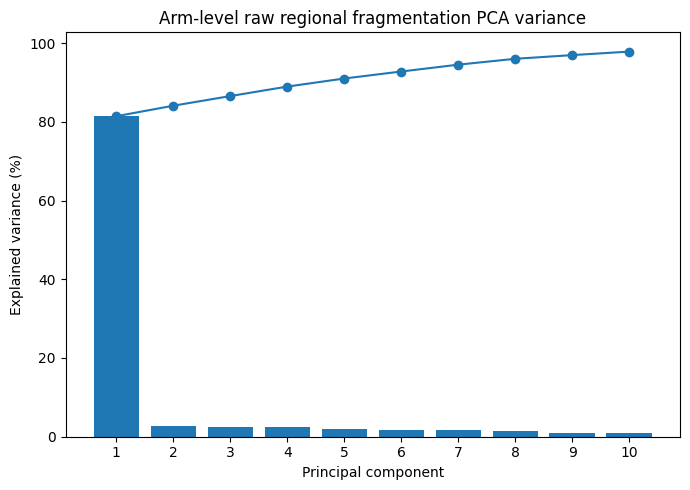

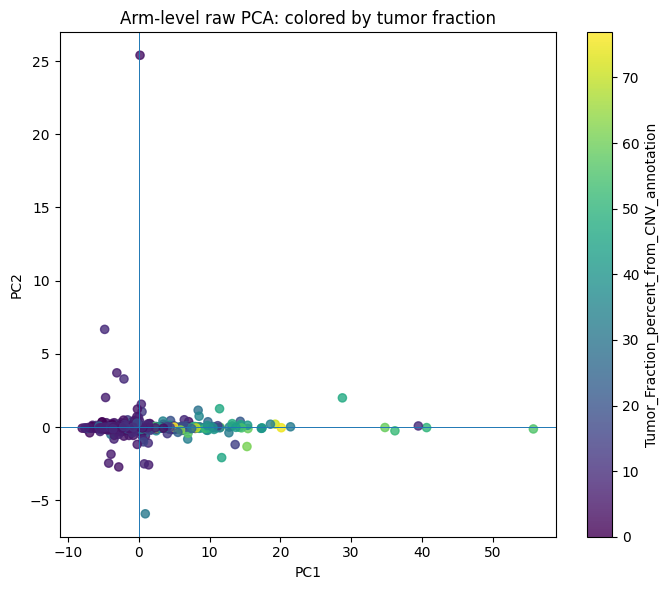

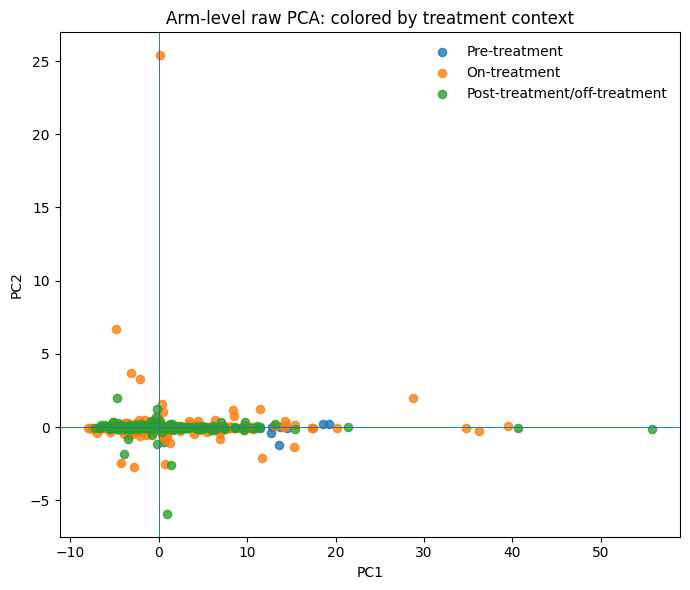

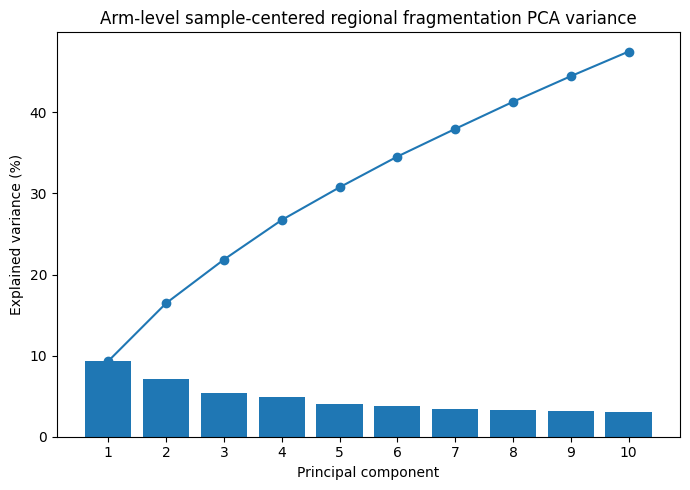

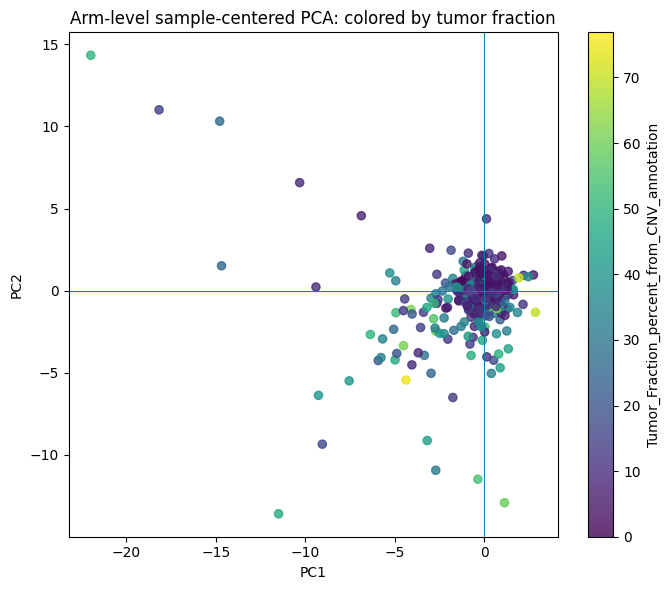

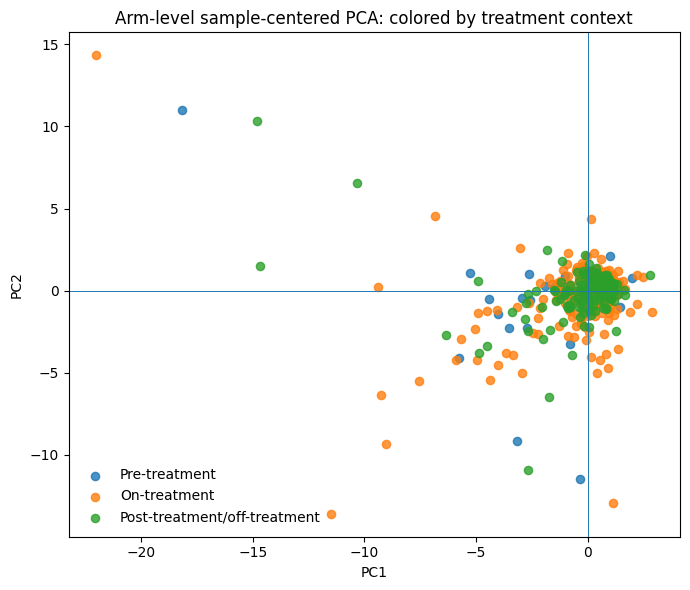

PCA plots saved to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step2_PCA_arm_chrom_models_plots


In [7]:

# ============================================================
# STEP 7: Generate PCA plots
# ============================================================

# Raw arm PCA
plot_pca_variance(
    pca_arm_raw_model,
    STEP2_PLOT_DIR / "02_pca_arm_raw_explained_variance.png",
    title="Arm-level raw regional fragmentation PCA variance",
)

plot_pca_scatter(
    pca_arm_raw_df,
    color_col=TFX_COL,
    path=STEP2_PLOT_DIR / "02_pca_arm_raw_PC1_PC2_by_tumor_fraction.png",
    title="Arm-level raw PCA: colored by tumor fraction",
)

plot_pca_scatter(
    pca_arm_raw_df,
    color_col="Treatment_Context_3group",
    path=STEP2_PLOT_DIR / "02_pca_arm_raw_PC1_PC2_by_treatment_context.png",
    title="Arm-level raw PCA: colored by treatment context",
)

# Sample-centered arm PCA
plot_pca_variance(
    pca_arm_centered_model,
    STEP2_PLOT_DIR / "02_pca_arm_sample_centered_explained_variance.png",
    title="Arm-level sample-centered regional fragmentation PCA variance",
)

plot_pca_scatter(
    pca_arm_centered_df,
    color_col=TFX_COL,
    path=STEP2_PLOT_DIR / "02_pca_arm_sample_centered_PC1_PC2_by_tumor_fraction.png",
    title="Arm-level sample-centered PCA: colored by tumor fraction",
)

plot_pca_scatter(
    pca_arm_centered_df,
    color_col="Treatment_Context_3group",
    path=STEP2_PLOT_DIR / "02_pca_arm_sample_centered_PC1_PC2_by_treatment_context.png",
    title="Arm-level sample-centered PCA: colored by treatment context",
)

print("PCA plots saved to:", STEP2_PLOT_DIR)


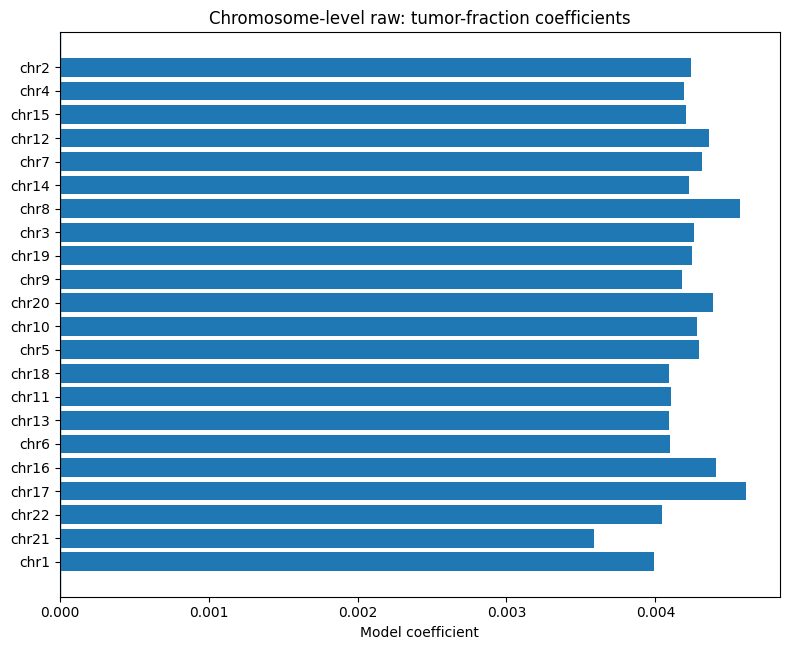

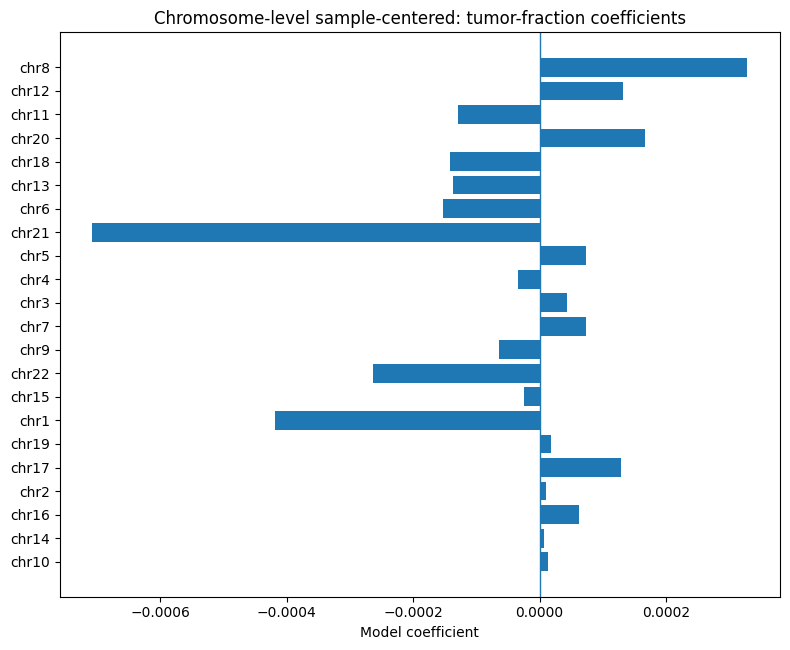

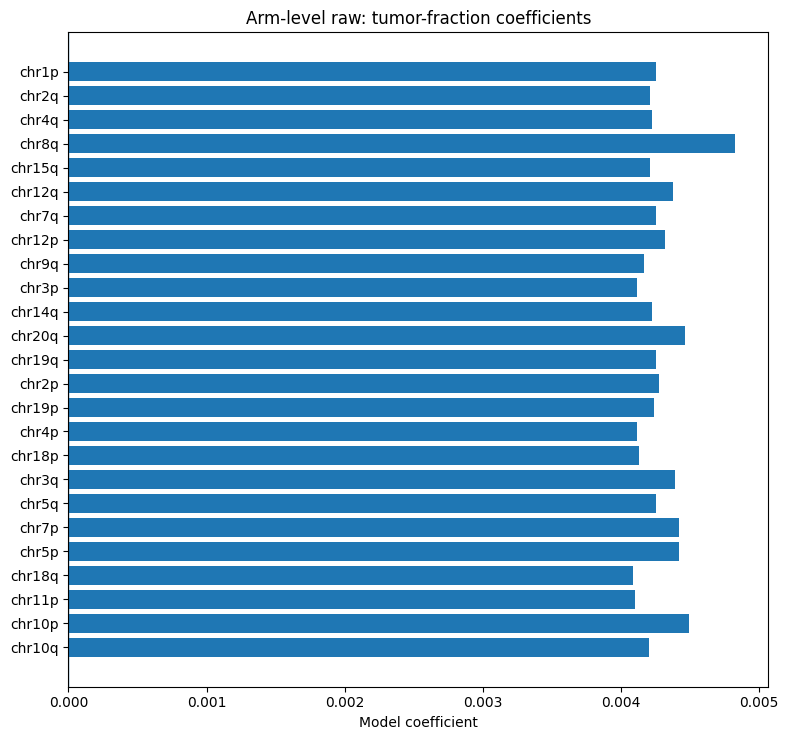

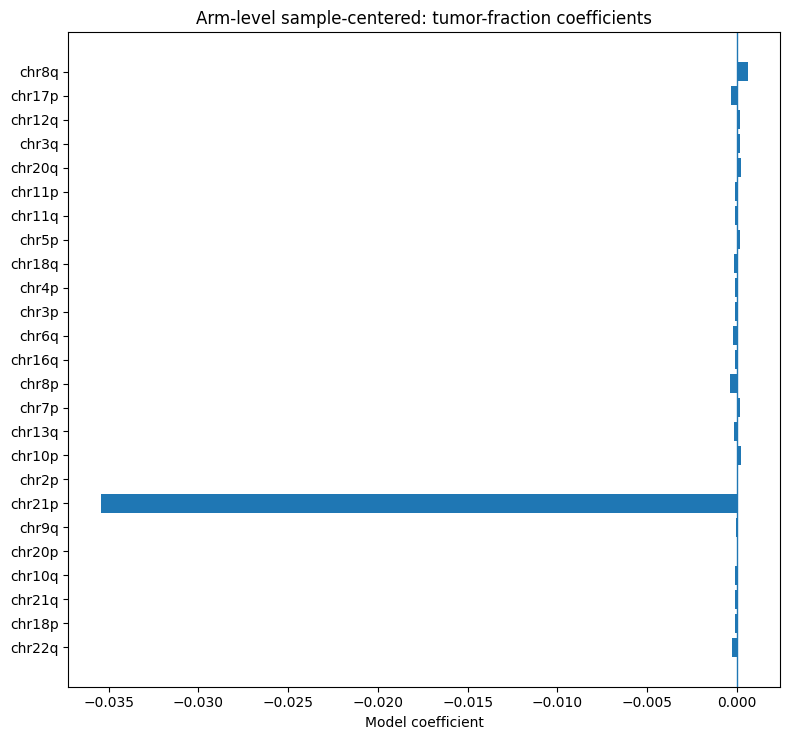

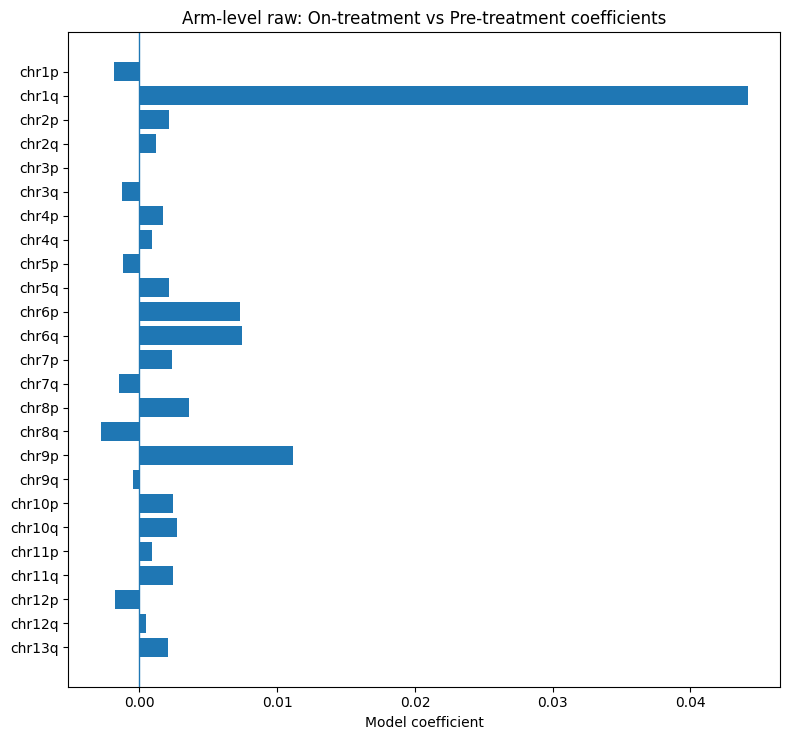

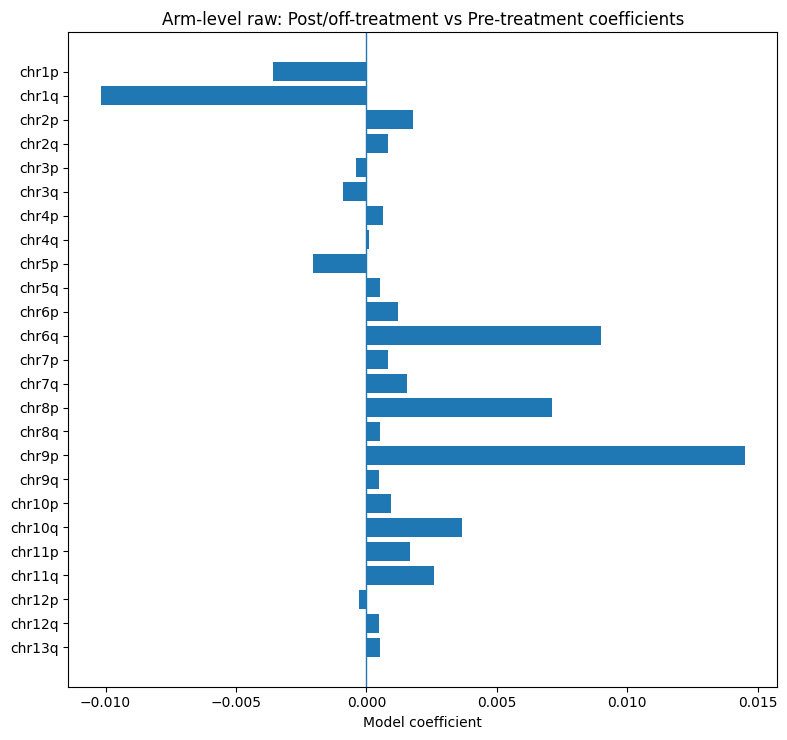

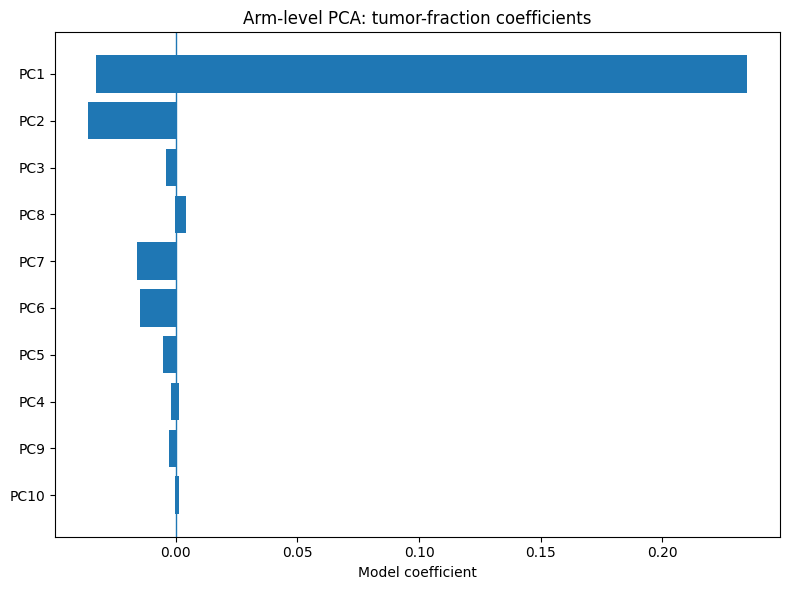

Coefficient plots saved to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step2_PCA_arm_chrom_models_plots


In [8]:

# ============================================================
# STEP 8: Generate model coefficient plots
# ============================================================

# Chromosome-level coefficients
plot_top_coefficients(
    chrom_results[chrom_results["matrix_type"].eq("raw")],
    coef_col="coef_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP2_PLOT_DIR / "02_chrom_raw_tumor_fraction_coefficients.png",
    title="Chromosome-level raw: tumor-fraction coefficients",
    top_n=22,
)

plot_top_coefficients(
    chrom_results[chrom_results["matrix_type"].eq("sample_centered")],
    coef_col="coef_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP2_PLOT_DIR / "02_chrom_sample_centered_tumor_fraction_coefficients.png",
    title="Chromosome-level sample-centered: tumor-fraction coefficients",
    top_n=22,
)

# Arm-level coefficients
plot_top_coefficients(
    arm_results[arm_results["matrix_type"].eq("raw")],
    coef_col="coef_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP2_PLOT_DIR / "02_arm_raw_tumor_fraction_coefficients.png",
    title="Arm-level raw: tumor-fraction coefficients",
    top_n=25,
)

plot_top_coefficients(
    arm_results[arm_results["matrix_type"].eq("sample_centered")],
    coef_col="coef_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP2_PLOT_DIR / "02_arm_sample_centered_tumor_fraction_coefficients.png",
    title="Arm-level sample-centered: tumor-fraction coefficients",
    top_n=25,
)

plot_top_coefficients(
    arm_results[arm_results["matrix_type"].eq("raw")],
    coef_col="coef_on_vs_pre",
    q_col="q_treatment_overall",
    path=STEP2_PLOT_DIR / "02_arm_raw_on_vs_pre_coefficients.png",
    title="Arm-level raw: On-treatment vs Pre-treatment coefficients",
    top_n=25,
)

plot_top_coefficients(
    arm_results[arm_results["matrix_type"].eq("raw")],
    coef_col="coef_post_off_vs_pre",
    q_col="q_treatment_overall",
    path=STEP2_PLOT_DIR / "02_arm_raw_post_off_vs_pre_coefficients.png",
    title="Arm-level raw: Post/off-treatment vs Pre-treatment coefficients",
    top_n=25,
)

# PCA coefficients
plot_top_coefficients(
    pca_model_results,
    coef_col="coef_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP2_PLOT_DIR / "02_pca_arm_tumor_fraction_coefficients.png",
    title="Arm-level PCA: tumor-fraction coefficients",
    top_n=20,
)

print("Coefficient plots saved to:", STEP2_PLOT_DIR)


In [9]:

# ============================================================
# STEP 9: Create combined Step 2 summary tables
# ============================================================

all_lowdim_results = pd.concat(
    [
        chrom_results,
        arm_results,
        pca_model_results,
    ],
    axis=0,
    ignore_index=True,
)

all_lowdim_results.to_csv(
    STEP2_TABLE_DIR / "02_all_lowdimensional_clustered_model_results.csv",
    index=False,
)

sig_treatment = all_lowdim_results[
    all_lowdim_results["q_treatment_overall"].lt(FDR_ALPHA)
].sort_values(["matrix_type", "q_treatment_overall"])

sig_tfx = all_lowdim_results[
    all_lowdim_results["q_tumor_fraction_percent"].lt(FDR_ALPHA)
].sort_values(["matrix_type", "q_tumor_fraction_percent"])

sig_treatment.to_csv(
    STEP2_TABLE_DIR / "02_significant_lowdimensional_treatment_context_FDR05.csv",
    index=False,
)

sig_tfx.to_csv(
    STEP2_TABLE_DIR / "02_significant_lowdimensional_tumor_fraction_FDR05.csv",
    index=False,
)

summary_rows = [
    {
        "metric": "total_lowdimensional_tests",
        "value": all_lowdim_results.shape[0],
    },
    {
        "metric": "significant_treatment_context_FDR05",
        "value": sig_treatment.shape[0],
    },
    {
        "metric": "significant_tumor_fraction_FDR05",
        "value": sig_tfx.shape[0],
    },
    {
        "metric": "chromosome_tests",
        "value": chrom_results.shape[0],
    },
    {
        "metric": "chromosome_arm_tests",
        "value": arm_results.shape[0],
    },
    {
        "metric": "pca_tests",
        "value": pca_model_results.shape[0],
    },
]

step2_summary = pd.DataFrame(summary_rows)
step2_summary.to_csv(STEP2_TABLE_DIR / "02_step2_results_summary.tsv", sep="\t", index=False)

print("Step 2 results summary:")
display(step2_summary)

print("\nSignificant treatment-context features:")
display(sig_treatment)

print("\nSignificant tumor-fraction features:")
display(sig_tfx)


Step 2 results summary:


,metric,value
0,total_lowdimensional_tests,146
1,significant_treatment_context_FDR05,0
2,significant_tumor_fraction_FDR05,80
3,chromosome_tests,44
4,chromosome_arm_tests,82
5,pca_tests,20



Significant treatment-context features:


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order



Significant tumor-fraction features:


,feature,feature_type,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,...,coef_post_off_vs_pre,p_post_off_vs_pre,coef_tumor_fraction_percent,p_tumor_fraction_percent,wald_chi2_treatment_overall,p_treatment_overall,q_treatment_overall,q_tumor_fraction_percent,max_abs_treatment_coef_vs_pre,feature_order
1,chr2,chromosome,raw,gee,750,260,74,491,185,ok,...,0.001204,0.913379,0.004236,3.216572e-22,0.029774,0.985223,0.998709,2.066178e-21,0.001556,2
3,chr4,chromosome,raw,gee,750,260,74,491,185,ok,...,0.000249,0.981767,0.004193,3.756687e-22,0.026260,0.986956,0.998709,2.066178e-21,0.001126,4
11,chr12,chromosome,raw,gee,750,260,74,491,185,ok,...,0.000294,0.979286,0.004361,2.910913e-22,0.002927,0.998537,0.998709,2.066178e-21,0.000294,12
14,chr15,chromosome,raw,gee,750,260,74,491,185,ok,...,0.001418,0.896910,0.004207,2.778722e-22,0.032409,0.983926,0.998709,2.066178e-21,0.001632,15
44,chr1p,chromosome_arm,raw,gee,750,260,74,491,185,ok,...,-0.003565,0.756129,0.004252,2.644990e-22,0.097980,0.952191,0.999583,2.278552e-21,0.003565,"(1, p)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,chr5p,chromosome_arm,sample_centered,gee,750,260,74,491,185,ok,...,-0.003007,0.137596,0.000196,2.580557e-03,2.250089,0.324638,0.857836,1.322536e-02,0.003007,"(5, p)"
142,PC7,PCA_arm,sample_centered,gee,750,260,74,491,185,ok,...,0.002177,0.989467,-0.015711,5.139085e-03,3.786040,0.150616,0.381907,1.713028e-02,0.173711,NaN
117,chr18q,chromosome_arm,sample_centered,gee,750,260,74,491,185,ok,...,-0.000703,0.667957,-0.000150,5.707741e-03,0.200349,0.904680,0.927297,2.600193e-02,0.000736,"(18, q)"
39,chr18,chromosome,sample_centered,gee,750,260,74,491,185,ok,...,-0.000579,0.718339,-0.000142,8.266718e-03,0.293915,0.863331,0.881582,3.637356e-02,0.000807,18


In [11]:

# ============================================================
# STEP 10: Save Step 2 scientific notes and interpretation template
# ============================================================

notes = f"""
AURORA regional fragmentation Step 2 notes

Purpose:
Step 2 tests whether low-dimensional regional fragmentation features are associated with
treatment context or tumor fraction while accounting for repeated blood draws from the same patient.

Features tested:
1. Chromosome-level mean regional short/long ratio
2. Chromosome-arm-level mean regional short/long ratio
3. Principal components derived from chromosome-arm-level regional fragmentation

Model:
regional_feature ~ Treatment context + Tumor fraction (%)
clustered by Patient_Identifier

Treatment-context reference group:
Pre-treatment

Model engine:
{MODEL_ENGINE}

Why this step comes before bin-level testing:
The regional matrix contains tens of thousands of genomic bins. Testing each bin directly creates a
large multiple-testing burden and may emphasize noisy local effects. Chromosome-level, arm-level,
and PCA summaries provide a lower-dimensional view of whether regional fragmentation contains
broad biological structure related to tumor burden or treatment context.

How to interpret tumor-fraction coefficients:
A positive tumor-fraction coefficient means that the regional feature increases with each 1 percentage-point
increase in tumor fraction, after adjusting for treatment context and repeated sampling.
A negative coefficient means that the regional feature decreases with increasing tumor fraction.

How to interpret treatment-context coefficients:
On-treatment and Post-treatment/off-treatment coefficients are interpreted relative to Pre-treatment,
after adjusting for tumor fraction and repeated sampling.

Important caution:
These analyses identify associations, not causal treatment effects. Treatment context is clinically
related to disease course and tumor burden, so tumor fraction adjustment is essential.

Notes:
Low-dimensional regional fragmentation features were evaluated using patient-clustered models.
Tumor fraction and treatment context were included in the same model to distinguish tumor-burden-associated
fragmentation patterns from treatment-context-associated differences. FDR correction was applied across
tested chromosome, chromosome-arm, and PCA features. Significant features were interpreted as candidate
regional fragmentation patterns for downstream bin-level and biological annotation analyses.

Output tables:
{STEP2_TABLE_DIR}

Output plots:
{STEP2_PLOT_DIR}
"""

notes_path = STEP2_TABLE_DIR / "02_step2_scientific_notes.txt"

with open(notes_path, "w") as fh:
    fh.write(notes.strip() + "\n")

print(notes)
print("Saved notes:", notes_path)
print("Step 2 notebook completed:", time.ctime())



AURORA regional fragmentation Step 2 notes

Purpose:
Step 2 tests whether low-dimensional regional fragmentation features are associated with
treatment context or tumor fraction while accounting for repeated blood draws from the same patient.

Features tested:
1. Chromosome-level mean regional short/long ratio
2. Chromosome-arm-level mean regional short/long ratio
3. Principal components derived from chromosome-arm-level regional fragmentation

Model:
regional_feature ~ Treatment context + Tumor fraction (%)
clustered by Patient_Identifier

Treatment-context reference group:
Pre-treatment

Model engine:
gee

Why this step comes before bin-level testing:
The regional matrix contains tens of thousands of genomic bins. Testing each bin directly creates a
large multiple-testing burden and may emphasize noisy local effects. Chromosome-level, arm-level,
and PCA summaries provide a lower-dimensional view of whether regional fragmentation contains
broad biological structure related to tumor b